# Домашнее задание: кластеризация

Ноутбук включает обе части исходного задания: кластеризацию точек из шести Excel-таблиц и сравнение MiniBatchKMeans с DBSCAN на синтетических данных.


In [1]:
# Нужно только в браузерном Jupyter (Pyodide / JupyterLite).
# В обычном Jupyter достаточно: pip install openpyxl xlrd
try:
    import micropip
    await micropip.install(["openpyxl", "xlrd"])
except ImportError:
    pass

## Часть 1. Кластеризация ЕГЭ по шести таблицам

По условию нужно построить распределения точек, разделить их на кластеры **вручную**, раскрасить кластеры, найти в каждом кластере точку с минимальной суммой расстояний до остальных точек (медоид) и усреднить координаты медоидов с умножением на 1000.

В таблицах №3 и №4 применяется манхэттенское расстояние, в остальных — евклидово. Код предлагает автоматическое начальное разбиение DBSCAN для проверки. Чтобы строго выполнить требование «вручную», просмотрите графики и при необходимости внесите свои метки в `manual_labels`.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import pairwise_distances

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

file_candidates = {
    "Таблица 0": ["0.xls", "0.xlsx", "converted/0.xlsx", "/mnt/data/0.xls", "/mnt/data/converted/0.xlsx"],
    "Таблица 1": ["1.xls", "1.xlsx", "converted/1.xlsx", "/mnt/data/1.xls", "/mnt/data/converted/1.xlsx"],
    "Таблица 2": ["2.xlsx", "/mnt/data/2.xlsx"],
    "Таблица 3": ["3.xlsx", "/mnt/data/3.xlsx"],
    "Таблица 4": ["4.xlsx", "/mnt/data/4.xlsx"],
    "Таблица 5": ["5.xlsx", "/mnt/data/5.xlsx"],
}

def find_file(candidates):
    for candidate in candidates:
        if os.path.exists(candidate):
            return candidate
    return None

def load_xy(path):
    # В одних файлах первая строка - заголовок X, Y, в других (2.xlsx, 3.xlsx) - уже данные.
    # Читаем без заголовка и выбрасываем только нечисловые строки, чтобы не терять первую точку.
    df = pd.read_excel(path, header=None).apply(pd.to_numeric, errors="coerce").dropna()
    if df.shape[1] < 2:
        raise ValueError(f"В {path} не найдено два числовых столбца.")
    return df.iloc[:, :2].to_numpy(dtype=float)

data_tables = {}
for title, candidates in file_candidates.items():
    path = find_file(candidates)
    if path is None:
        print(f"{title}: файл не найден. Загрузите Excel в папку ноутбука.")
        continue
    try:
        data_tables[title] = load_xy(path)
        print(f"{title}: {len(data_tables[title])} точек ({path})")
    except Exception as e:
        print(f"{title}: не удалось прочитать {path}: {e}")

Таблица 0: 100 точек (0.xls)
Таблица 1: 9999 точек (1.xls)
Таблица 2: 1000 точек (2.xlsx)
Таблица 3: 10000 точек (3.xlsx)
Таблица 4: 500 точек (4.xlsx)
Таблица 5: 9999 точек (5.xlsx)


### 1.1 Исходные графики

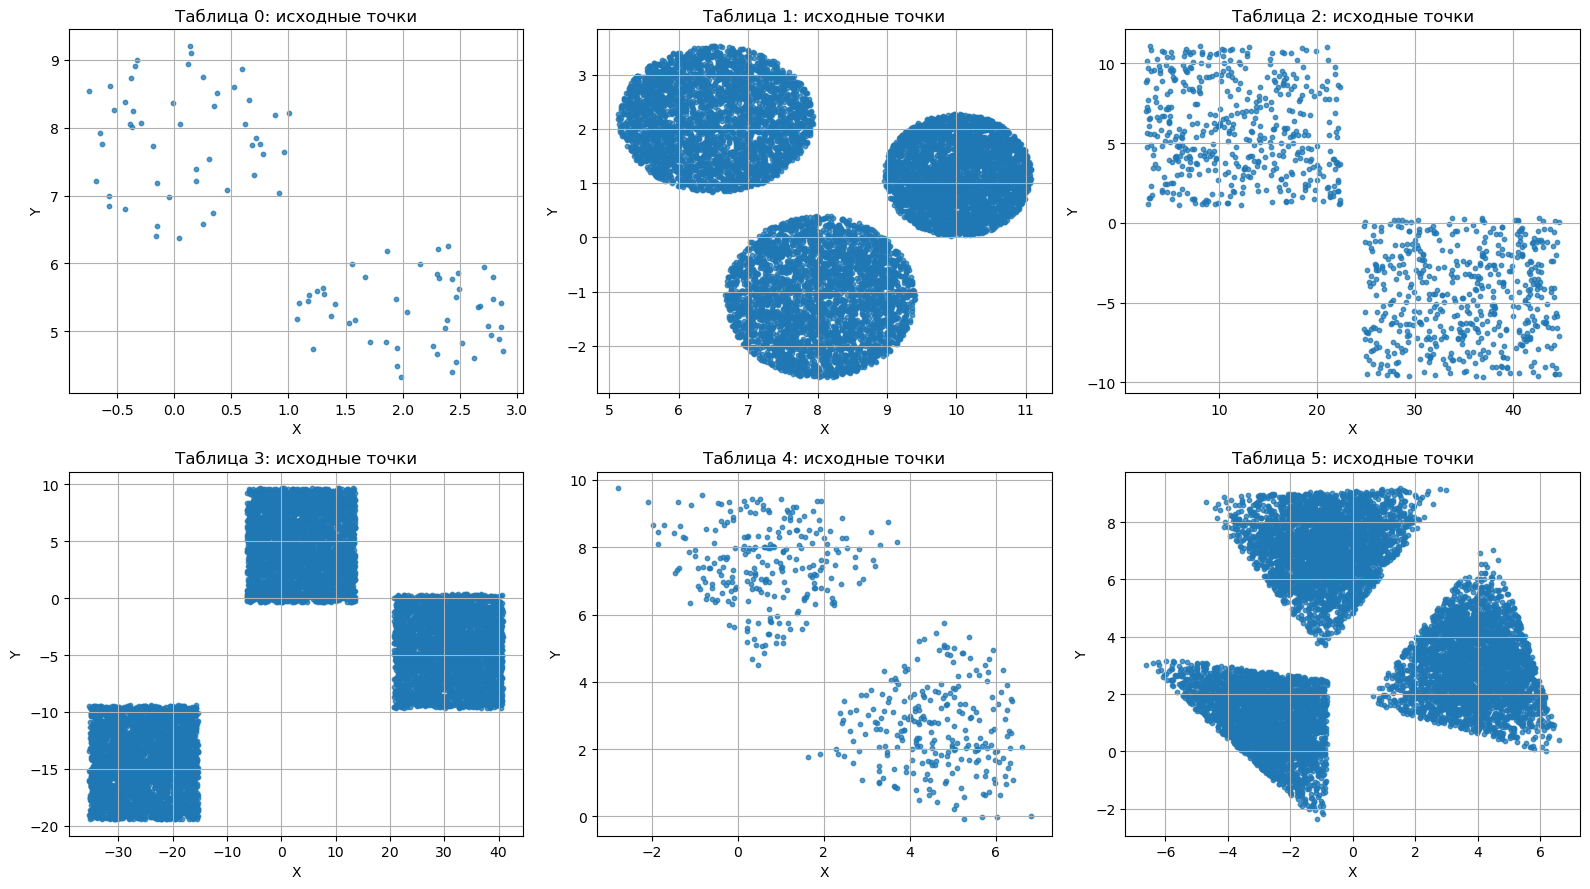

In [3]:
if data_tables:
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax in axes.flat:
        ax.set_visible(False)
    for ax, (title, points) in zip(axes.flat, data_tables.items()):
        ax.set_visible(True)
        ax.scatter(points[:, 0], points[:, 1], s=10, alpha=0.75)
        ax.set_title(f"{title}: исходные точки")
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
    plt.tight_layout()
    plt.show()


### 1.2 Ручное разбиение на кластеры и поиск медоидов

Границы кластеров заданы вручную многоугольниками по графикам. Многоугольники сделаны с запасом, чтобы покрыть всё облако точек: после разбиения каждая точка должна попасть ровно в один кластер (проверяется в коде, нераспределённых точек быть не должно).

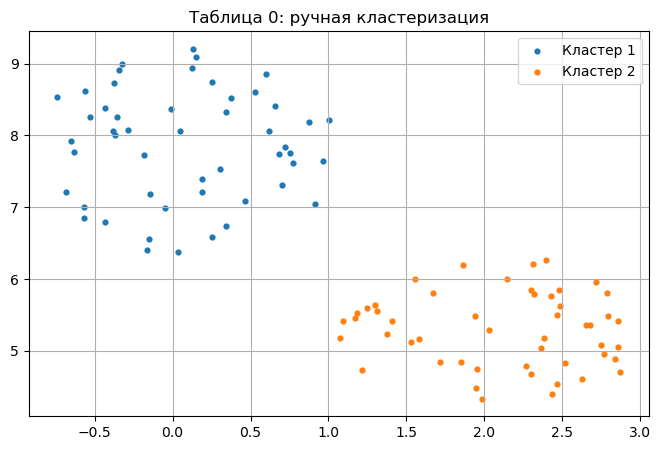

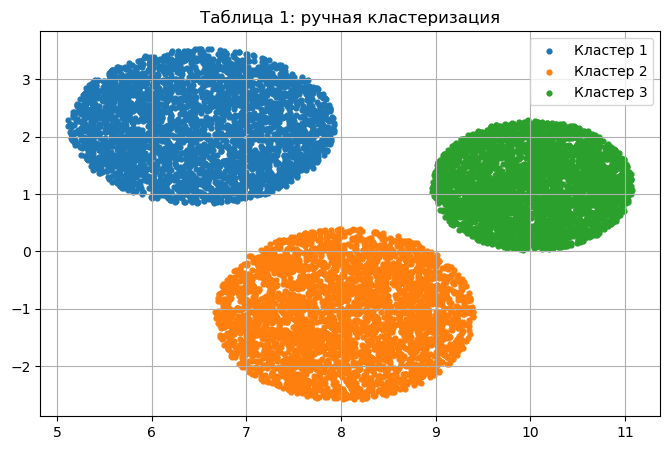

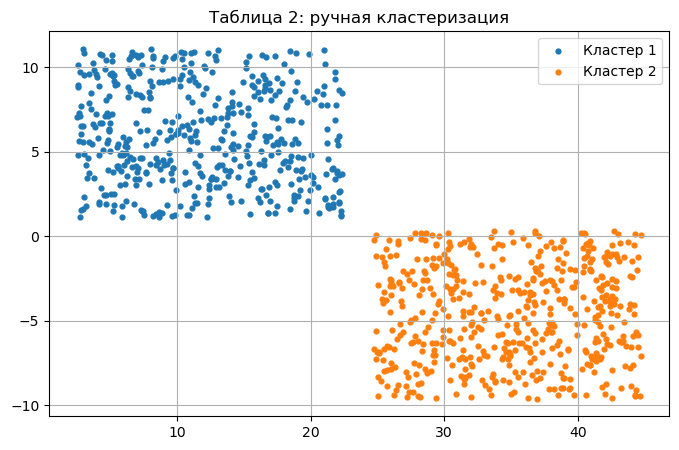

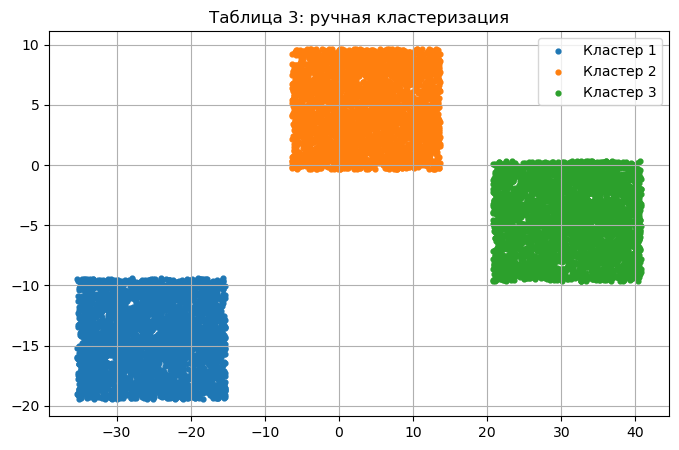

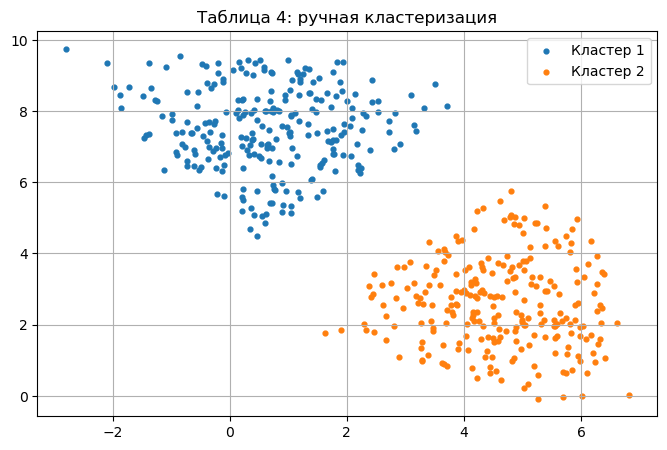

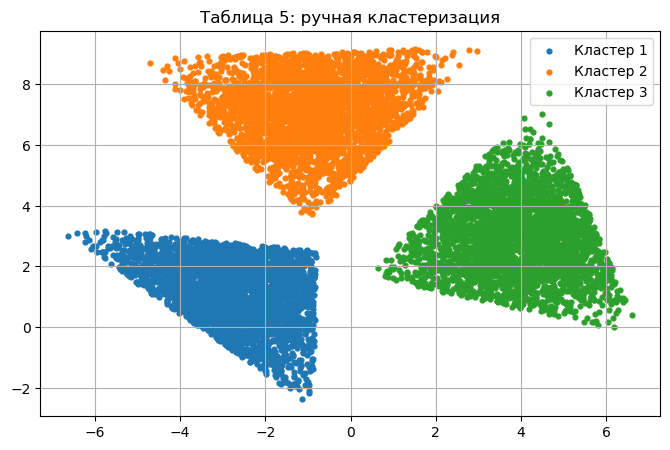

,Таблица,Кластер,X медоида,Y медоида,Количество точек
0,Таблица 0,1,0.048112,8.053051,50
1,Таблица 0,2,2.033901,5.289296,50
2,Таблица 1,1,6.469983,2.169761,3333
3,Таблица 1,2,8.040075,-1.108706,3333
4,Таблица 1,3,10.022535,1.154201,3333
5,Таблица 2,1,11.334080,5.965961,476
6,Таблица 2,2,34.926351,-4.695276,524
7,Таблица 3,1,-25.130758,-14.413328,3429
8,Таблица 3,2,3.517911,4.653696,3284
9,Таблица 3,3,30.849529,-4.517203,3287


In [4]:
from matplotlib.path import Path as PolygonPath
from sklearn.metrics import pairwise_distances
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Границы кластеров заданы вручную по графикам (вершины многоугольников).
manual_polygons = {
    "Таблица 0": [
        [[-3, 3], [-3, 12], [1.04, 12], [1.04, 3]],
        [[1.04, 3], [1.04, 12], [5, 12], [5, 3]],
    ],
    "Таблица 1": [
        [[3, 0.6], [3, 5], [8.6, 5], [8.6, 0.6]],
        [[3, 0.6], [8.6, 0.6], [9.0, 0.4], [9.5, -0.3], [9.8, -0.6], [12, -0.6], [12, -5], [3, -5]],
        [[8.6, 0.6], [8.6, 5], [12, 5], [12, -0.6], [9.8, -0.6], [9.5, -0.3], [9.0, 0.4]],
    ],
    "Таблица 2": [
        [[0, -15], [0, 15], [23.5, 15], [23.5, -15]],
        [[23.5, -15], [23.5, 15], [50, 15], [50, -15]],
    ],
    "Таблица 3": [
        [[-45, -30], [-45, 15], [-10, 15], [-10, -30]],
        [[-10, -30], [-10, 15], [17, 15], [17, -30]],
        [[17, -30], [17, 15], [50, 15], [50, -30]],
    ],
    "Таблица 4": [
        [[-5, 4.495], [-5, 12], [3.9, 12], [3.9, 4.495]],
        [[-5, -3], [-5, 4.495], [3.9, 4.495], [3.9, 12], [9, 12], [9, -3]],
    ],
    "Таблица 5": [
        [[-9, 3.5], [-9, -4], [0.0, -4], [0.0, 3.5]],
        [[-9, 3.5], [0.0, 3.5], [1.5, 3.5], [6, 9.5], [6, 12], [-9, 12]],
        [[0.0, -4], [0.0, 3.5], [1.5, 3.5], [6, 9.5], [10, 9.5], [10, -4]],
    ],
}

# Метрика расстояния для каждой таблицы
metrics = {
    "Таблица 0": "euclidean",
    "Таблица 1": "euclidean",
    "Таблица 2": "euclidean",
    "Таблица 3": "manhattan",
    "Таблица 4": "manhattan",
    "Таблица 5": "euclidean",
}

medoid_rows = []

for title, points in data_tables.items():
    distances = pairwise_distances(points, metric=metrics[title])

    fig, ax = plt.subplots(figsize=(8, 5))

    for number, vertices in enumerate(manual_polygons[title], start=1):
        # точки внутри многоугольника - это один кластер
        indices = np.where(PolygonPath(vertices).contains_points(points))[0]
        ax.scatter(points[indices, 0], points[indices, 1], s=12, label=f"Кластер {number}")

        # медоид: точка с минимальной суммой расстояний до остальных точек кластера
        sums = distances[np.ix_(indices, indices)].sum(axis=1)
        medoid_index = indices[np.argmin(sums)]

        medoid_rows.append({
            "Таблица": title,
            "Кластер": number,
            "X медоида": points[medoid_index, 0],
            "Y медоида": points[medoid_index, 1],
            "Количество точек": len(indices),
        })

    ax.set_title(title + ": ручная кластеризация")
    ax.legend()
    plt.show()

medoids = pd.DataFrame(medoid_rows)
display(medoids)

### 1.3 Итоговый расчёт

In [5]:
if len(medoids):
    mean_x = medoids["X медоида"].mean()
    mean_y = medoids["Y медоида"].mean()

    print("Средняя X × 1000:", mean_x * 1000)
    print("Средняя Y × 1000:", mean_y * 1000)

Средняя X × 1000: 5831.5836628996685
Средняя Y × 1000: 1580.9782106604987


## Часть 2. Кластеризация: MiniBatchKMeans и DBSCAN

На предложенных распределениях данных проверяются два алгоритма (реализации из sklearn). Для каждой пары «алгоритм-данные» строится график, разные кластеры покрашены в разные цвета, чёрным отмечен шум DBSCAN. Параметры подобраны так, чтобы алгоритмы можно было сравнивать (одинаковое число кластеров). Ноутбук построен по шаблону из задания.

In [6]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [7]:
# Объекты алгоритмов создаются здесь, а параметры (число кластеров, eps, min_samples)
# подставляются для каждого набора данных внутри цикла через set_params.
two_means = cluster.MiniBatchKMeans(n_init=10, random_state=0)
dbscan = cluster.DBSCAN()

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


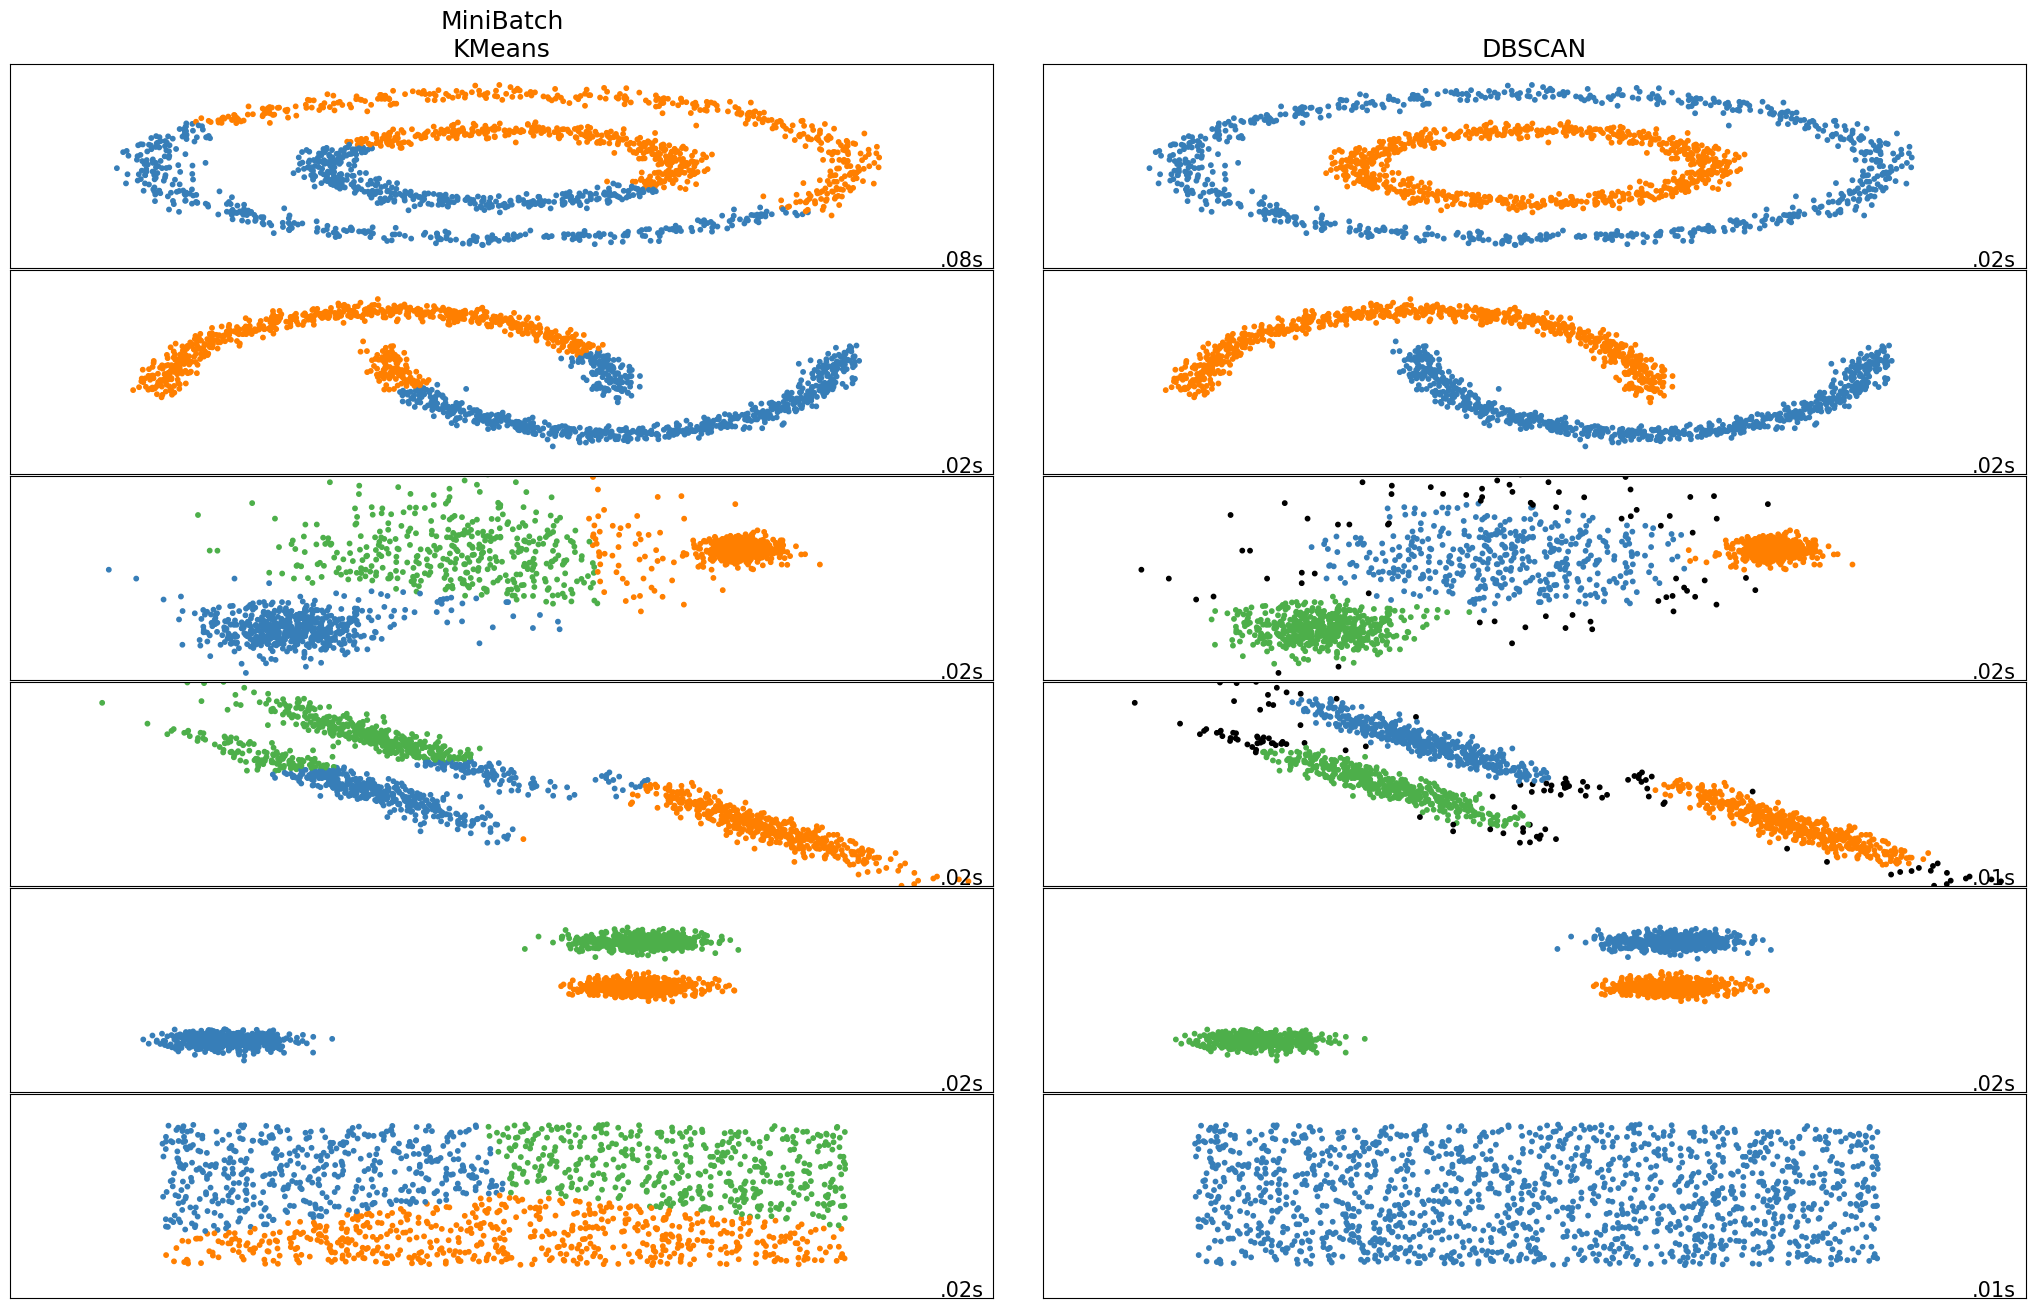

In [8]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

all_datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.20,
            "n_neighbors": 2,
            "min_samples": 8,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 20,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(all_datasets):
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    X = StandardScaler().fit_transform(X)

    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    connectivity = 0.5 * (connectivity + connectivity.T)

    # параметры алгоритмов для текущего набора данных
    two_means.set_params(n_clusters=params["n_clusters"])
    dbscan.set_params(eps=params["eps"], min_samples=params["min_samples"])

    for name, algorithm in clustering_algorithms:
        t0 = time.time()
        algorithm.fit(X)
        t1 = time.time()

        y_pred = algorithm.labels_.astype(int)

        plt.subplot(len(all_datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        colors = np.array(
            list(
                islice(
                    cycle(
                        [
                            "#377eb8",
                            "#ff7f00",
                            "#4daf4a",
                            "#f781bf",
                            "#a65628",
                            "#984ea3",
                            "#999999",
                            "#e41a1c",
                            "#dede00",
                        ]
                    ),
                    int(max(y_pred) + 1),
                )
            )
        )
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])

        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        plt.text(
            0.99,
            0.01,
            ("%.2fs" % (t1 - t0)).lstrip("0"),
            transform=plt.gca().transAxes,
            size=15,
            horizontalalignment="right",
        )
        plot_num += 1

plt.show()

## Вывод

Строки на графике по порядку: круги, полумесяцы, разная плотность, анизотропные группы, компактные группы, без структуры.

- **Круги и полумесяцы.** MiniBatchKMeans делит данные прямой линией и режет фигуры пополам, а DBSCAN выделяет обе фигуры правильно, потому что опирается на плотность и связность, а не на расстояние до центра.
- **Разная плотность.** Единый `eps` у DBSCAN плохо подходит для кластеров с разным разбросом: с параметрами из шаблона (`eps=0.18`, `min_samples=5`) он находил только 2 кластера, поэтому параметры изменены на `eps=0.20`, `min_samples=8`. Тогда получаются 3 кластера и немного шума.
- **Анизотропные группы.** MiniBatchKMeans предполагает округлые кластеры и на вытянутых группах ошибается на границах. DBSCAN справляется заметно лучше, но часть точек уходит в шум (чёрные).
- **Компактные группы.** Оба алгоритма дают практически одинаковое разбиение на 3 кластера.
- **Без структуры.** Правильного разбиения нет. MiniBatchKMeans всё равно режет облако на 3 части, а DBSCAN объявляет всё одним кластером. Результат определяется параметрами алгоритма, а не данными.
- **Общее.** MiniBatchKMeans быстрый, но число кластеров нужно задавать заранее, и он подходит для компактных округлых групп. DBSCAN находит группы произвольной формы и выделяет шум, но чувствителен к `eps` и `min_samples`.